In [1]:
from ase.io.trajectory import Trajectory 
from ase.md.langevin import Langevin 
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution 

import numpy as np 
from mace.calculators import mace_mp,mace_off 
from chgnet.model.dynamics import CHGNetCalculator 
from chgnet.model import CHGNet 
from ase import units 

/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.


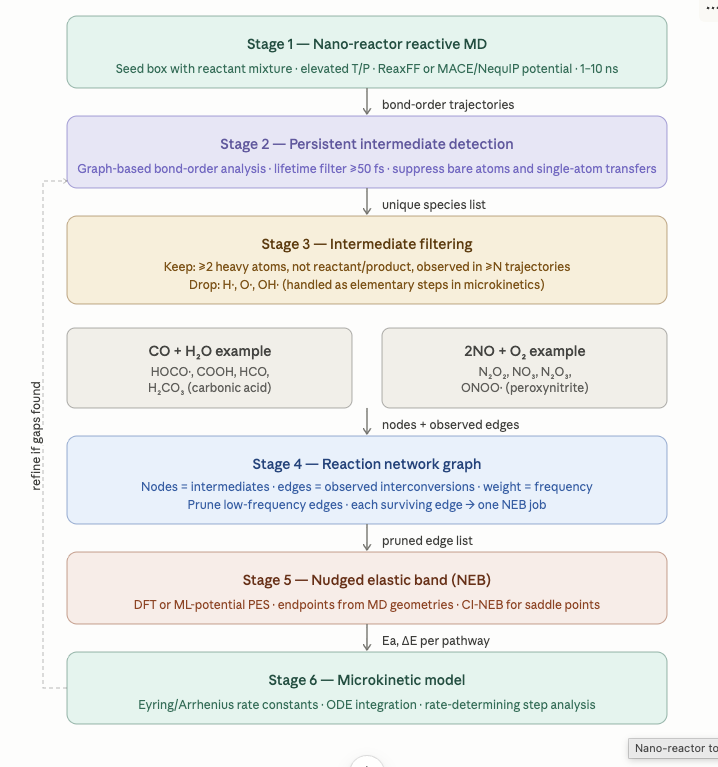

In [2]:

    
def run_nanoreactor(
        atoms=None,
        calculator=None,
        temperature = 4000, 
        n_steps = 50000,
        timestep_fs = 0.5, 
        traj_interval=10,
        friction=0.01,
):
    lo = atoms.cell.lengths()[0]

    def nanoreactor_pulse():
        step = dyn.nsteps

        scale = 0.85 + 0.15*np.sin(
        2*np.pi*step/5000
        )

        newcell = np.eye(3) * lo * scale
        atoms.set_cell(newcell, scale_atoms=True)

        traj.write()
    
    
    atoms.calc = calculator 
    MaxwellBoltzmannDistribution(atoms,temperature_K=temperature)
    dyn = Langevin(
        atoms,
        timestep=timestep_fs * units.fs,
        temperature_K=temperature,
        friction=friction / units.fs
    )
    traj = Trajectory("./nanoreactor.traj","w",atoms)
    dyn.attach(nanoreactor_pulse,interval=traj_interval)

    dyn.run(n_steps)




In [3]:
from smilesbox.smilesbox import SMILESbox

In [4]:
sm = SMILESbox(smiles=["O=C=O","[HH]"],box_size=10)
atoms = sm.atoms

In [5]:
from ase.visualize import view 

view(atoms,viewer="ngl")

In [6]:
calculator = mace_off(model="small",default_dtype="float32")

run_nanoreactor(atoms,calculator,n_steps=10000)

/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/mace/calculators/mace.py:199: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Using MACE-OFF23 MODEL for MACECalculator with /Users/badw/.cache/mace/MACE-OFF23_small.model
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.


/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/ase/md/langevin.py:110: FutureWarning: The implementation of `fixcm=True` in `Langevin` does not strictly sample the correct NVT distributions. The deviations are typically small for large systems but can be more pronounced for small systems. Use `fixcm=False` together with `ase.constraints.FixCom`. `fixcm` is deprecated since ASE 3.28.0 and will be removed in a future release.
  warnings.warn(msg, FutureWarning)


from claude

In [28]:
SMILESbox?

Init signature:
SMILESbox(
    smiles: str | list[str] | tuple[str, ...],
    box_size: float = 20.0,
    min_distance: float = 2.0,
    random_rotate: bool = True,
    axis: str = 'x',
    margin: float = 1.5,
)
Docstring:      <no docstring>
File:           ~/github-projects/smilesbox/src/smilesbox/smilesbox.py
Type:           type
Subclasses:     

In [39]:
from smilesbox.smilesbox import SMILESbox
sm = SMILESbox(
    #smiles=["[N]=O", "[N]=O", "O=O", "[N]=O", "[N]=O", "O=O"],
    #smiles = ["N","N","N","N","O=O","O=O","O=O","O=O","O=O"]*2,
   #smiles = ["[HH]","[HH]","O=O",]*4,
   smiles = ["[C-]#[O+]","O"]*2,
    box_size=20,
    min_distance=1.0
)
atoms = sm.atoms

In [40]:
calculator = CHGNetCalculator(use_device="mps")

CHGNet v0.3.0 initialized with 412,525 parameters
CHGNet will run on mps



NanoReactor starting
  10 atoms | T=4500 K | NVT
  8000 steps × 0.25 fs = 2.0 ps
  τ_min = 10 fs | BO cutoffs = defaults (0.3)
  Output → reactor_output

Running MD...


/Users/badw/miniconda3/envs/py312/lib/python3.12/site-packages/ase/md/langevin.py:110: FutureWarning: The implementation of `fixcm=True` in `Langevin` does not strictly sample the correct NVT distributions. The deviations are typically small for large systems but can be more pronounced for small systems. Use `fixcm=False` together with `ase.constraints.FixCom`. `fixcm` is deprecated since ASE 3.28.0 and will be removed in a future release.
  warnings.warn(msg, FutureWarning)


  [SpeciesTracker] processed 500 frames, 4 unique formulae seen


Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will

  [SpeciesTracker] processed 1000 frames, 5 unique formulae seen


...

  [SpeciesTracker] processed 7500 frames, 8 unique formulae seen


Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong
Structure graph_id=None has 1 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will

  [SpeciesTracker] processed 8000 frames, 8 unique formulae seen

MD complete in 521.4 s  (65.18 ms/step)

Building reaction network...
[ReactionNetwork] 16 raw transitions → 16 after min_count≥2 filter

NANO-REACTOR ANALYSIS REPORT

Simulation: 2.0 ps | T = 4500 K | τ_min = 10 fs

Reactants (excluded): ['CO', 'H2O']
Products  (excluded): ['CO2', 'H2']

[SpeciesTracker] Intermediates passing all filters (τ_min=10 fs, heavy≥2, freq≥0.0%):

[!] No intermediates found — consider lowering τ_min or BO cutoff

NEB job list (16 pairs):
          Source  →  Target          Observed
  ----------------------------------------------
              HO  →  H2O                  374
             H2O  →  HO                   374
              HO  →  O                     95
               O  →  HO                    94
            CHO2  →  CO2                   49
             H2O  →  O                     43
             CO2  →  CHO2                  39
               O  →  H2O                   37
  

Structure graph_id=None has 2 isolated atom(s) with atom_graph_cutoff=6. CHGNet calculation will likely go wrong


Network plot → reactor_output/reaction_network.png


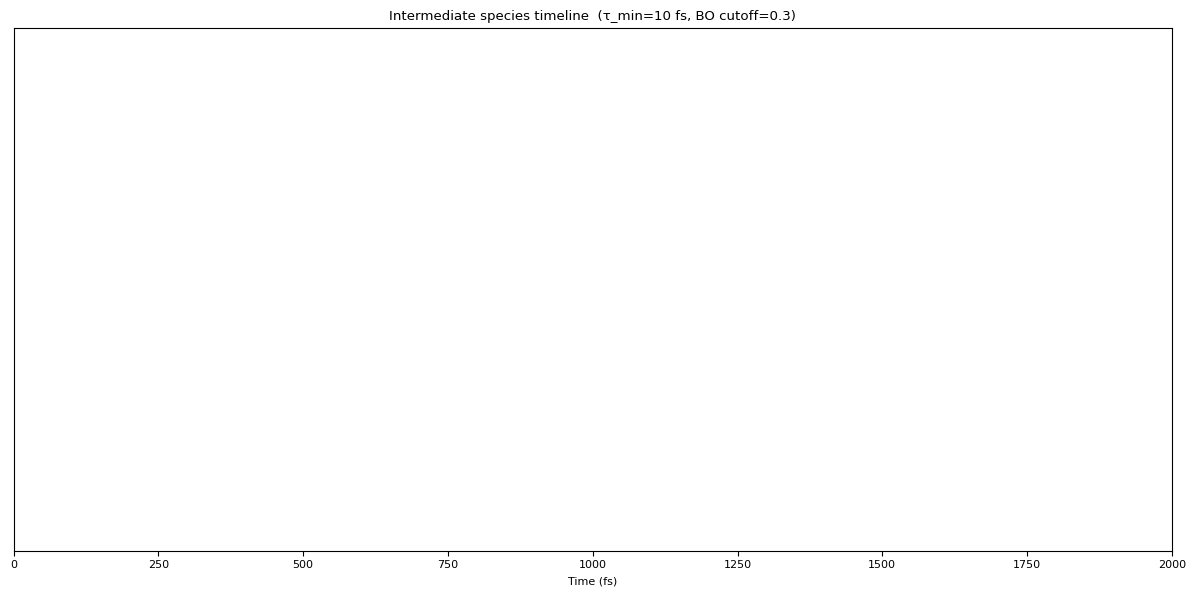

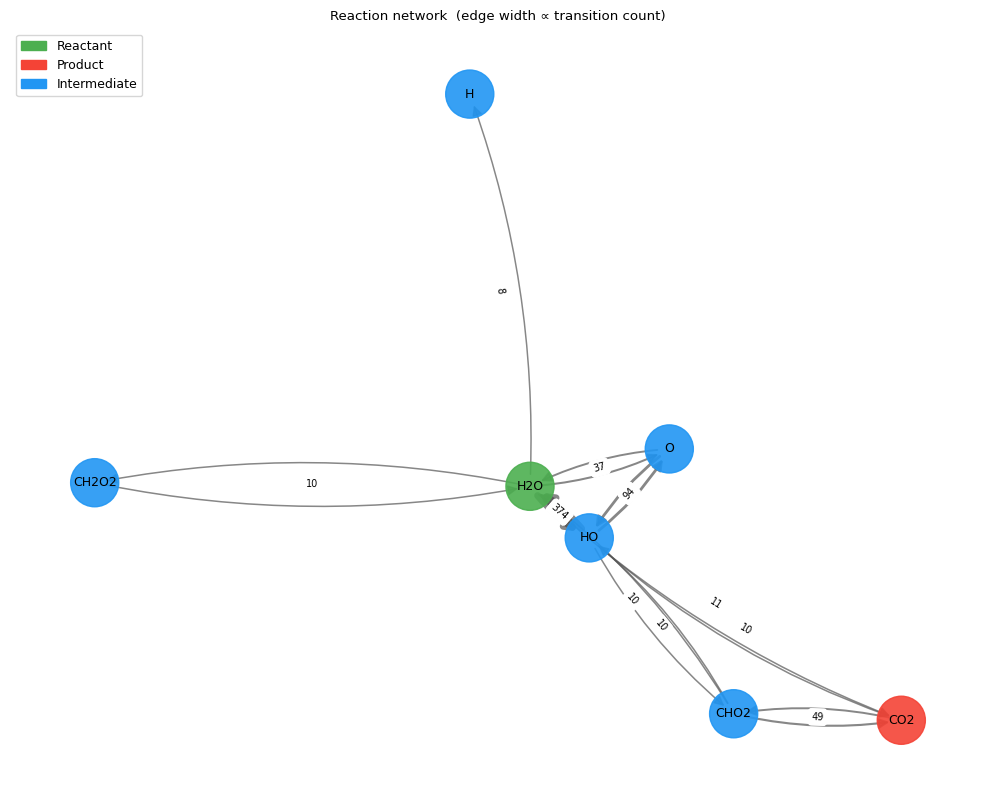

In [41]:
from ase.io import read
from nano_reactor import NanoReactor

# Your pre-built simulation cell (ASE Atoms)

# Your reactive calculator — replace EMT with the real one

reactor = NanoReactor(
    atoms        = atoms,
    calculator   = calculator,
    temperature  = 4500,          # K
    total_time_fs= 2000,       # 100 ps
    timestep_fs  = 0.25,
    tau_min_fs   = 10,
    reactants    = {"CO", "H2O"},
    products     = {"CO2",'H2'},
    output_dir   = "reactor_output",
)

reactor.run()
reactor.report()
reactor.plot()